## Segment Blastocyste

Blastocyst image with two channels (DAPI for DNA und LAMIN-B1 for nuclear boundary). 

The data used for this notebook is licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) and are © Blin et al.


- [data](https://idr.openmicroscopy.org/webclient/?show=image-6001240)
- [metdata](https://github.com/IDR/idr0062-blin-nuclearsegmentation/blob/HEAD/experimentA/idr0062-experimentA-annotation.csv)

In [1]:
import importlib.metadata

print(importlib.metadata.version("cellpose"))

4.2.1.1


In [2]:
from bioio import BioImage
import bioio_tifffile
from skimage import exposure, io, measure
import matplotlib.pyplot as plt
import cellpose
from cellpose import models, core, utils, io, plot
import numpy as np
import pyclesperanto as cle
from pyclesperanto import imshow
import matplotlib.pyplot as plt
from skimage.segmentation import find_boundaries
import tifffile

### Load Image

In [3]:
img1 = BioImage('images/B1_C1.tif')

In [4]:
img1.dims

<Dimensions [T: 1, C: 2, Z: 236, Y: 275, X: 271]>

In [5]:
img1.standard_metadata

StandardMetadata(binning=None, column=None, dimensions_present='ZCYX', image_size_c=2, image_size_t=None, image_size_x=271, image_size_y=275, image_size_z=236, imaged_by=None, imaging_date=None, objective=None, pixel_size_x=0.36039815346402093, pixel_size_y=0.36039815346402093, pixel_size_z=0.5002025531914894, position_index=None, row=None, timelapse=False, timelapse_interval=None, total_time_duration=None)

In [6]:
img1_lazy_load = img1.get_image_dask_data("CZYX", T=0) 

In [7]:
img1_astro = img1_lazy_load[:, :, :, :]

In [9]:
print(img1_astro.shape)

(2, 236, 275, 271)


In [10]:
img1_final = img1_astro.compute()

### Segment

In [14]:
model = models.CellposeModel(gpu=True)

In [15]:
print(model.pretrained_model)

/home/sc.uni-leipzig.de/lk80xeku/.cellpose/models/cpsam_v2


In [ ]:
#masks_img1, flows_img1, styles_img1 = model.eval(img1_final, do_3D=True,  channel_axis=0, z_axis=1)

In [16]:
%%time
masks_img1, flows_img1, styles_img1 = model.eval(img1_final, do_3D=True,  channel_axis=0, z_axis=1)

CPU times: user 4min 1s, sys: 608 ms, total: 4min 2s
Wall time: 4min 4s


In [26]:
#io.imsave('masks/B1_C1_masks.tif', masks_img1.astype('uint16')) 

In [35]:
tifffile.imwrite(
    'masks/B1_C1_masks_test.tif',
    masks_img1.astype('uint16'),
    metadata={'axes': 'ZYX'}
)

### Check image

In [27]:
print(img1_final.shape)
print(masks_img1.shape)

(2, 236, 275, 271)
(236, 275, 271)


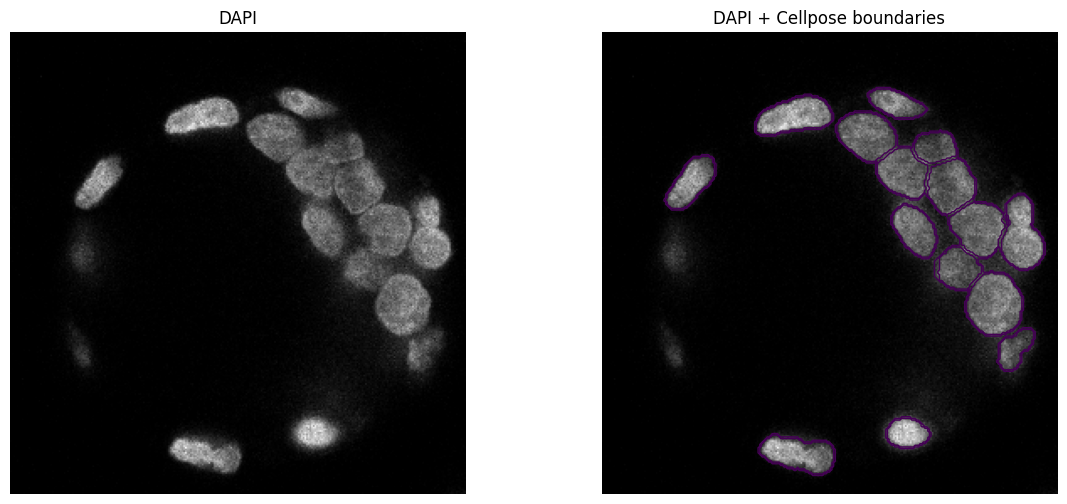

In [32]:
z = 100

# DAPI channel
image_slice = img1_final[1, z, :, :]
# Cellpose mask
mask_slice = masks_img1[z, :, :]
# Get only the boundaries
boundaries = find_boundaries(mask_slice, mode="outer")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Original
ax[0].imshow(image_slice, cmap="gray")
ax[0].set_title("DAPI")

# Overlay boundaries
ax[1].imshow(image_slice, cmap="gray")
ax[1].contour(boundaries, levels=[0.5], linewidths=1)
ax[1].set_title("DAPI + Cellpose boundaries")

for a in ax:
    a.axis("off")

plt.show()